In [1]:
%matplotlib inline

# Visualizations: normative behavioral data

This notebook includes code and instructions to re-generate figures included in the Data Descriptor article for the CNeuroMod-emotion-videos dataset. These figures include:
- **Emotional category counts**: normative categorical scores related to emotions.
- **Affective dimensions distributions**: normative affective scores collected using 9-point likert scales.

# 0 | Installation

### 0.1 | Install required Python libraries
To run this Notebook and re-create figures, you need to install the following Python libraries (e.g., inside a virtual environment). 

```shell
jupyter==1.0.0
numpy==2.4.1
pandas==3.0.0
matplotlib==3.10.8
seaborn==0.13.2
pybids==0.21.0
cmcrameri==1.8
```
<br/>

---

### 0.2 | Download the behavioral data

Categorical and dimensional affective ratings were previously collected on the stimuli in another study ([Cowen & Keltner, 2017](https://doi.org/10.1073/pnas.1702247114)). 

The stimuli and the mean ratings can be requested from these authors by filling [this form](https://goo.gl/forms/XErJw9sBeyuOyp5Q2). The ratings provided by these authors can be found in the `CowenKeltnerEmotionalVideos.csv` file. The code below is assuming that this file has been placed at the root of the stimuli submodule.

The behavioral ratings were then organized in the events files provided for each run:
- `cneuromod-emotion-videos/emotion-videos/sub-*/ses-*/func/*events.tsv`. 


---
### 0.3 | Launch the Jupyter Notebook

Inside `cneuromod-emotion-videos`, navigate to the tutorial section, and open the current Jupyter Notebook (visu_ratings.ipynb)

```bash
cd cneuromod-emotion-videos/datapaper/notebooks
jupyter notebook
```
<br/>

---
# 1 | Import Python libraries

Run the code below to import Python libraries.

In [9]:
import warnings
warnings.filterwarnings('ignore')

import os
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from cmcrameri import cm
from bids import BIDSLayout

---
# 2 | Normative behavioral ratings for the experimental stimulus subset (Figure XX, XX panel)

**Fig. XX (XX)** Normative behavioral ratings for the experimental stimulus subset.

**Input files**: 
* cneuromod.emotion-videos.raw/sub-\*/ses-\*/func/\*events.tsv
* emotions.stimuli/CowenKeltnerEmotionalVideos.csv

### 2.1 | Set paths and variables

If the downloaded `CowenKeltnerEmotionalVideos.csv` has not been placed in the emotions.stimuli submodule, please replace the value of the `stimuli_path` variable to specify the directory in which this file lives.

In [3]:
input_path = Path("../../cneuromod.emotion-videos.raw").resolve()
layout_input = BIDSLayout(input_path, validate=False)

stimuli_path = Path("../../emotions.stimuli")
original_ratings = pd.read_csv(os.path.join(stimuli_path, 'CowenKeltnerEmotionalVideos.csv'))
original_ratings = original_ratings[original_ratings.columns[:49]]
original_ratings.columns = original_ratings.columns.str.lower()

output_path = Path('../figures/beh').resolve()
output_path.mkdir(parents=True, exist_ok=True)

### 2.2 | Run the code below to generate Fig. XX (XX)

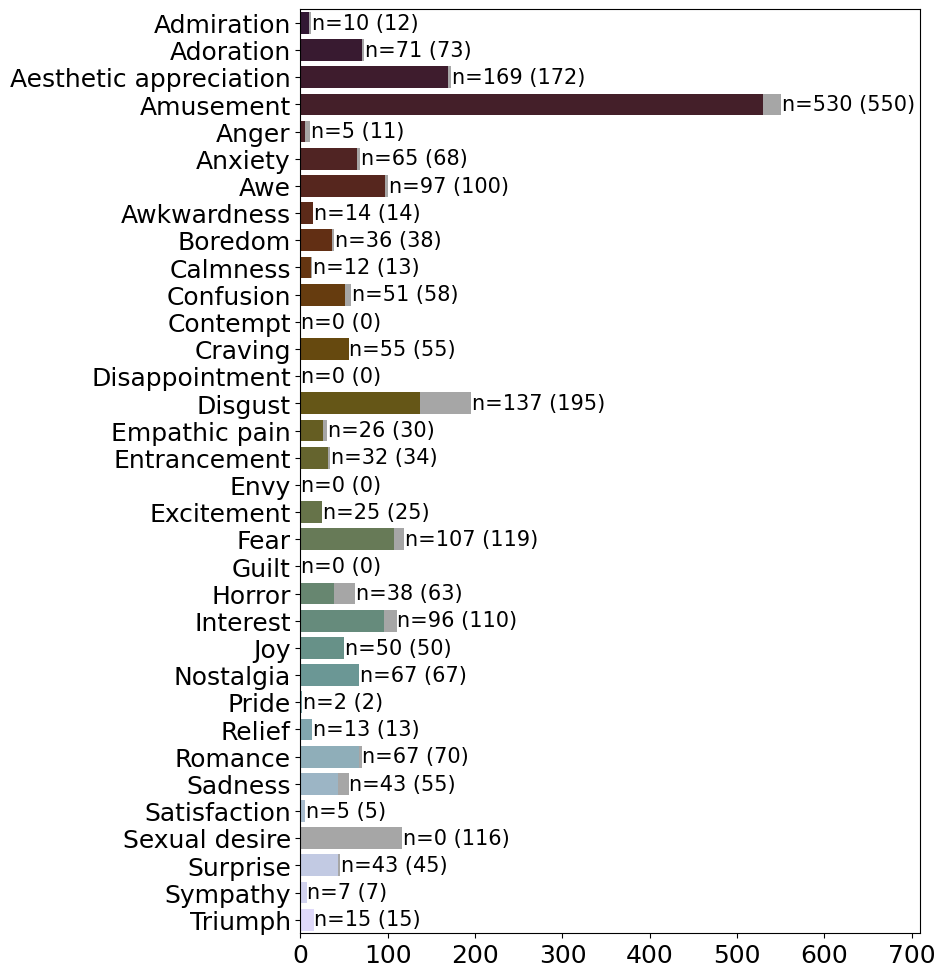

In [4]:
# We only need to get the events files from one subject since they are
# the same for all subjects, just in a different order. For the figures
# generated in this notebook, the order does not matter.
files = layout_input.get(subject='01', suffix='events', extension='tsv')
ratings, ratings_dim = pd.DataFrame(), pd.DataFrame()

category = [
    'admiration','adoration','aesthetic appreciation','amusement','anger','anxiety','awe','awkwardness',
    'boredom','calmness','confusion','contempt','craving','disappointment', 'disgust',
    'empathic pain','entrancement','envy','excitement','fear','guilt','horror','interest','joy',
    'nostalgia','pride','relief','romance','sadness','satisfaction','sexual desire','surprise','sympathy','triumph'
]


# Retrieve ratings
for file in files:
    events = pd.read_csv(file, sep='\t')
    ratings = pd.concat([ratings, events[[*category, 'stim_file']]])
    ratings_dim = pd.concat([ratings_dim, events[[*dimension, 'stim_file']]])
    
# Plot categories count
c_map_cat = sns.color_palette(cm.glasgow.resampled(len(category)).colors)
c_map_dim = sns.color_palette(cm.glasgow.resampled(len(dimension)).colors)

primary_cat_ratings = ratings[category].idxmax(axis=1)
primary_cat_original_ratings = original_ratings[category].idxmax(axis=1)

plt.figure(figsize=(8, 12))
sns.countplot(primary_cat_original_ratings, alpha=0.7, color='grey', order=category)
sns.countplot(primary_cat_ratings, order=category, palette=c_map_cat)

## Tune figure parameters
locs, labels = plt.yticks()
plt.yticks(locs, [label.get_text().capitalize() for label in labels], fontsize=18)
plt.xticks(fontsize=18)
plt.xlabel('')

## Add number of observations
for i, cat in enumerate(category):
    subset_counts = len(primary_cat_ratings[primary_cat_ratings==cat])
    original_counts = len(primary_cat_original_ratings[primary_cat_original_ratings==cat])
    
    txt = f"n={subset_counts} ({original_counts})"
    
    plt.text(
        x=original_counts+1,
        y=i,
        s=txt,
        va='center',
        fontsize=15
    )
    
plt.xlim([0, 710])

plt.savefig(
    os.path.join(
        output_path,
        'task-emotion_desc-categoryCount.svg'
    ),
    transparent=True, dpi=600
)

### 2.3 | Run the code below to generate Fig. XX (XX)

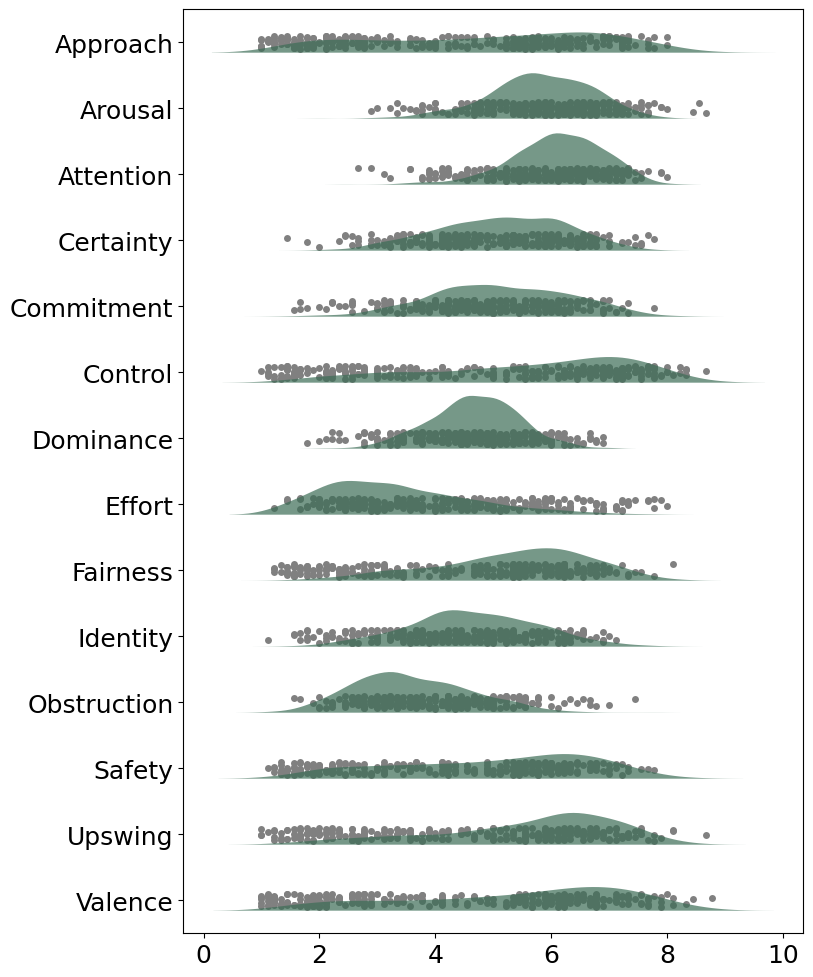

In [11]:
np.random.seed(42)

dimension = [
    'approach','arousal','attention','certainty','commitment','control',
    'dominance','effort','fairness','identity','obstruction','safety',
    'upswing','valence'
]

#Plot dimension ratings distributions
color_vp = cm.batlow.resampled(10).colors[3]

# Reshape dataframe
ratings_dim_long = pd.melt(ratings_dim, value_vars=dimension)
original_ratings_tmp = original_ratings[~original_ratings['filename'].isin(ratings_dim['stim_file'])]
original_ratings_long = pd.melt(original_ratings_tmp[dimension], value_vars=dimension)

plt.figure(figsize=(8,12))
ax = sns.violinplot(data=ratings_dim_long, x='value', y='variable', hue=True, hue_order=[True, False], split=True, alpha=0.7, linewidth=0, palette={True: color_vp, False: color_vp}, saturation=1)
ax = sns.stripplot(data=original_ratings_long, x='value', y='variable', jitter=True,color='grey', zorder=0)
ax.legend_ = None

## Align violinplot with y ticks
y_offset = -0.25 
for collection in ax.collections:
    if 'PolyCollection' in str(type(collection)):
        paths = collection.get_paths()
        for path in paths:
            path.vertices[:, 1] += y_offset

## Tune figure parameters
locs, labels = plt.yticks()
plt.yticks(locs, [label.get_text().capitalize() for label in labels], fontsize=18)
plt.xticks(fontsize=18)
plt.xlabel('')
plt.ylabel('')

plt.savefig(
    os.path.join(
        output_path,
        'task-emotion_desc-dimensionDistributions.svg'
    ),
    transparent=True, dpi=600
)